# Применение NoisyNets в задачах обучения с подкреплением

**Промежуточное исследование по МГМО**  
Горбунов Иван Олегович, ИУ6-74б  
Руководитель: Кудрявцев Сергей Александрович  
11 ноября 2026 года

На этом этапе реализован NoisyNet-DQN и проведено сравнение с ε-жадным DQN. Выполнены десять запусков на CartPole-v1. Ноутбук проверяет реализацию и анализирует их исходные журналы. Серия на более сложной среде и абляции относятся к следующему этапу.

In [1]:
from pathlib import Path
import sys, json, tempfile
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display, Image
from noisynets.networks import NoisyLinear, QNetwork
from noisynets.train import Config, run, evaluate
from noisynets.evaluate import load_checkpoint
from noisynets.analysis import load_runs, summarise
ROOT = Path.cwd()
if not (ROOT / "configs/pilot.json").exists():
    ROOT = ROOT.parent
assert (ROOT / "configs/pilot.json").exists()
torch.set_num_threads(1)
print("Python:", sys.version.split()[0], "Torch:", torch.__version__)
print("Среда:", json.loads((ROOT / "configs/pilot.json").read_text())["env"])

Python: 3.12.14 Torch: 2.15.0
Среда: CartPole-v1


## 1. Постановка эксперимента

Сравниваются сети одинаковой топологии 4 → 64 → 64 → 2. В NoisyNet два последних линейных слоя заменены на шумовые. Данные генерируются взаимодействием со средой: отдельного обучающего датасета нет.

Каждый метод получает 30 000 шагов среды. Для обучения используются seed 0–4. При одном seed методы имеют одинаковые начальные средние веса и образуют пару для сравнения; промежуточная оценка — пять эпизодов каждые 3 000 шагов. Итоговая оценка последнего чекпойнта проводится на двадцати отложенных эпизодах. В основной оценке исследование отключается: ε = 0 и средние веса μ соответственно.

Это практический вариант NoisyNet-DQN, а не буквальное воспроизведение Atari-протокола статьи. В частности, применяется Huber loss, шум обновляется перед каждым действием, а градиент — раз в четыре шага.

In [2]:
config = json.loads((ROOT / "configs/pilot.json").read_text())
display(pd.Series(config, name="Значение").to_frame())

,Значение
env,CartPole-v1
steps,30000
hidden,64
learning_rate,0.001
gamma,0.99
batch_size,64
replay_capacity,50000
learning_starts,1000
train_frequency,4
target_interval,500


## 2. Параметрический шум

Для шумового слоя:

$$y=(\mu^w+\sigma^w\odot\varepsilon^w)x+\mu^b+\sigma^b\odot\varepsilon^b.$$

При факторизации используются два независимых стандартных нормальных вектора:

$$\varepsilon^w_{ji}=f(u_i)f(v_j),\quad\varepsilon^b_j=f(v_j),\quad f(x)=\operatorname{sign}(x)\sqrt{|x|}.$$

Обучаются μ и σ. Число исходных случайных значений уменьшается с pq + q до p + q. σ — коэффициент масштаба, а не непосредственно стандартное отклонение итогового факторизованного шума. Инициализация весов: σ₀/√p; смещений: σ₀/√q.

In [3]:
torch.manual_seed(42)
layer = NoisyLinear(4, 2)
layer.reset_noise()
x = torch.ones(3, 4)
y1 = layer(x).detach().clone()
assert torch.equal(y1, layer(x))
layer.reset_noise()
y2 = layer(x).detach().clone()
assert not torch.equal(y1, y2)
layer(x).square().mean().backward()
print("Градиент σ ненулевой:", bool(layer.weight_sigma.grad.abs().sum() > 0))
layer.eval()
expected = torch.nn.functional.linear(x, layer.weight_mu, layer.bias_mu)
assert torch.allclose(layer(x), expected)
print("eval() использует средние веса:", True)

Градиент σ ненулевой: True
eval() использует средние веса: True


## 3. Проверка цикла обучения

Для проверки полного цикла модель обучается на 256 шагах, после чего сохраняются и проверяются результаты. Временный каталог удаляется после проверки. Данные основной серии находятся в `results/pilot`; команды запуска приведены в README.

In [4]:
with tempfile.TemporaryDirectory(prefix="noisynets-example-") as directory:
    output = Path(directory) / "run"
    smoke = Config(algorithm="noisy", seed=123, steps=256,
                   learning_starts=64, batch_size=32, replay_capacity=512,
                   eval_interval=128, eval_episodes=2, final_episodes=2)
    run(smoke, output)
    assert (output / "COMPLETE").exists()
    display(pd.read_csv(output / "evaluations.csv"))
    print("Обновлений градиента:", json.loads((output / "metadata.json").read_text())["gradient_updates"])

noisy seed=123 step=0: 9.5


noisy seed=123 step=128: 9.5


noisy seed=123 step=256: 9.5


,step,return_mean,return_std,epsilon,sigma_abs_layers.2,sigma_abs_layers.4
0,0,9.5,0.707107,0.0,0.062500,0.062500
1,128,9.5,0.707107,0.0,0.062463,0.062360
2,256,9.5,0.707107,0.0,0.062415,0.061949


Обновлений градиента: 49


## 4. Данные всех независимых экспериментов

Единицей повторения является запуск обучения. Двадцать оценочных эпизодов одной модели описывают эту модель и не заменяют двадцать независимых обучений. SD в сводке рассчитывается между пятью средними по seed. Для итоговой оценки использованы seed среды 20 000–20 019, не участвовавшие в промежуточной оценке.

Для интервала разности методов используется парный bootstrap: при перевыборке сохраняются две модели с одним seed и общей инициализацией. Это пять независимых пар, а не сто независимых обучений по числу оценочных эпизодов.

In [5]:
runs, curves = load_runs(ROOT / "results/pilot")
assert len(runs) == 10
assert set(runs.seed) == {0, 1, 2, 3, 4}
assert runs.groupby("algorithm").size().eq(5).all()
display(runs[["algorithm", "seed", "final_mean", "final_episode_sd", "auc_mean", "trainable_parameters"]].round(2))

,algorithm,seed,final_mean,final_episode_sd,auc_mean,trainable_parameters
0,dqn,0,136.75,6.66,162.57,4610
1,dqn,1,134.40,8.83,195.14,4610
2,dqn,2,100.75,4.20,192.27,4610
3,dqn,3,118.25,6.16,205.84,4610
4,dqn,4,199.95,54.82,187.77,4610
5,noisy,0,151.35,28.29,162.60,8900
6,noisy,1,163.80,16.26,124.77,8900
7,noisy,2,103.65,5.99,121.56,8900
8,noisy,3,116.30,9.35,168.53,8900
9,noisy,4,139.25,9.69,119.69,8900


## 5. Кривые обучения

Каждая точка — средняя оценка пяти текущих моделей, для каждой модели проведено пять эпизодов. Заливка показывает ± одно стандартное отклонение между запусками. Для обеих серий показана одна шкала 0–500. Между точками не выполнялась дополнительная оценка.

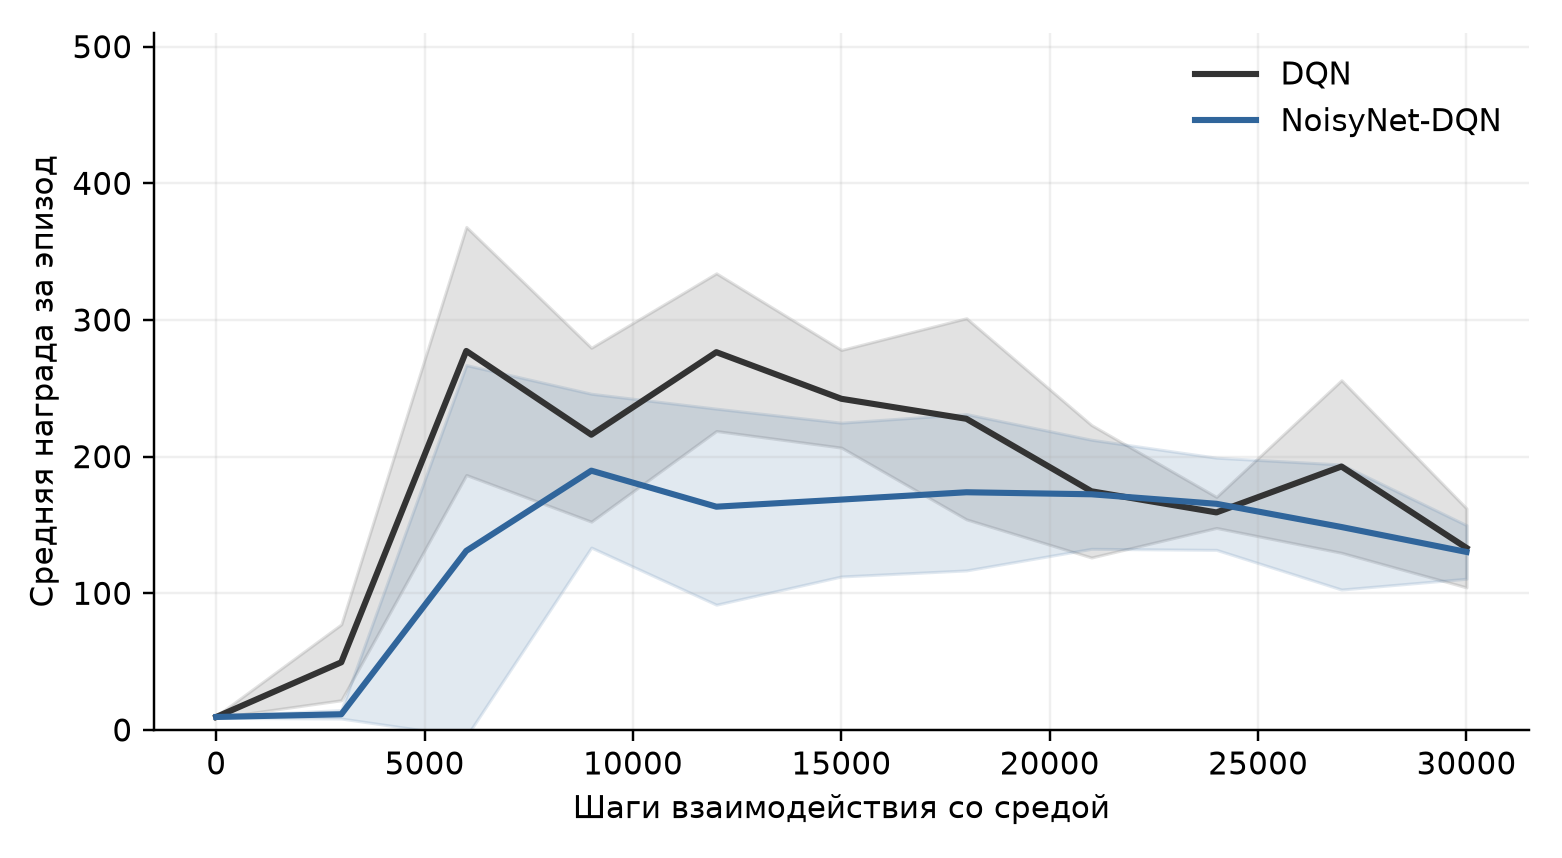

mean     std
algorithm step                 
dqn       0        9.48    0.63
          3000    49.48   27.78
          6000   277.32   90.76
          9000   216.04   63.63
          12000  276.44   57.70
          15000  242.32   35.73
          18000  227.68   73.60
          21000  174.64   48.48
          24000  159.16   11.35
          27000  192.76   63.14
          30000  133.20   28.90
noisy     0        9.48    0.63
          3000    11.44    3.11
          6000   131.04  135.93
          9000   189.72   56.29
          12000  163.36   71.73
          15000  168.56   56.27
          18000  173.92   57.21
          21000  172.44   39.92
          24000  165.48   33.72
          27000  148.48   45.75
          30000  130.24   19.61

In [6]:
display(Image(filename=str(ROOT / "results/analysis/figures/learning_curves.png")))
validation = curves.groupby(["algorithm", "step"]).return_mean.agg(["mean", "std"])
display(validation.round(2))

## 6. Итоговая награда и эффективность по шагам

AUC здесь означает площадь под ломаной промежуточных оценок, делённую на 30 000. Она выражается в единицах награды и показывает средний уровень кривой в пределах заданного бюджета. 

В итоговом сравнении используются модели после 30 000 шагов обучения.

,algorithm,n_seeds,final_mean,final_seed_sd,auc_mean,auc_seed_sd
0,dqn,5,138.02,37.52,188.72,16.06
1,noisy,5,134.87,24.73,139.43,24.02


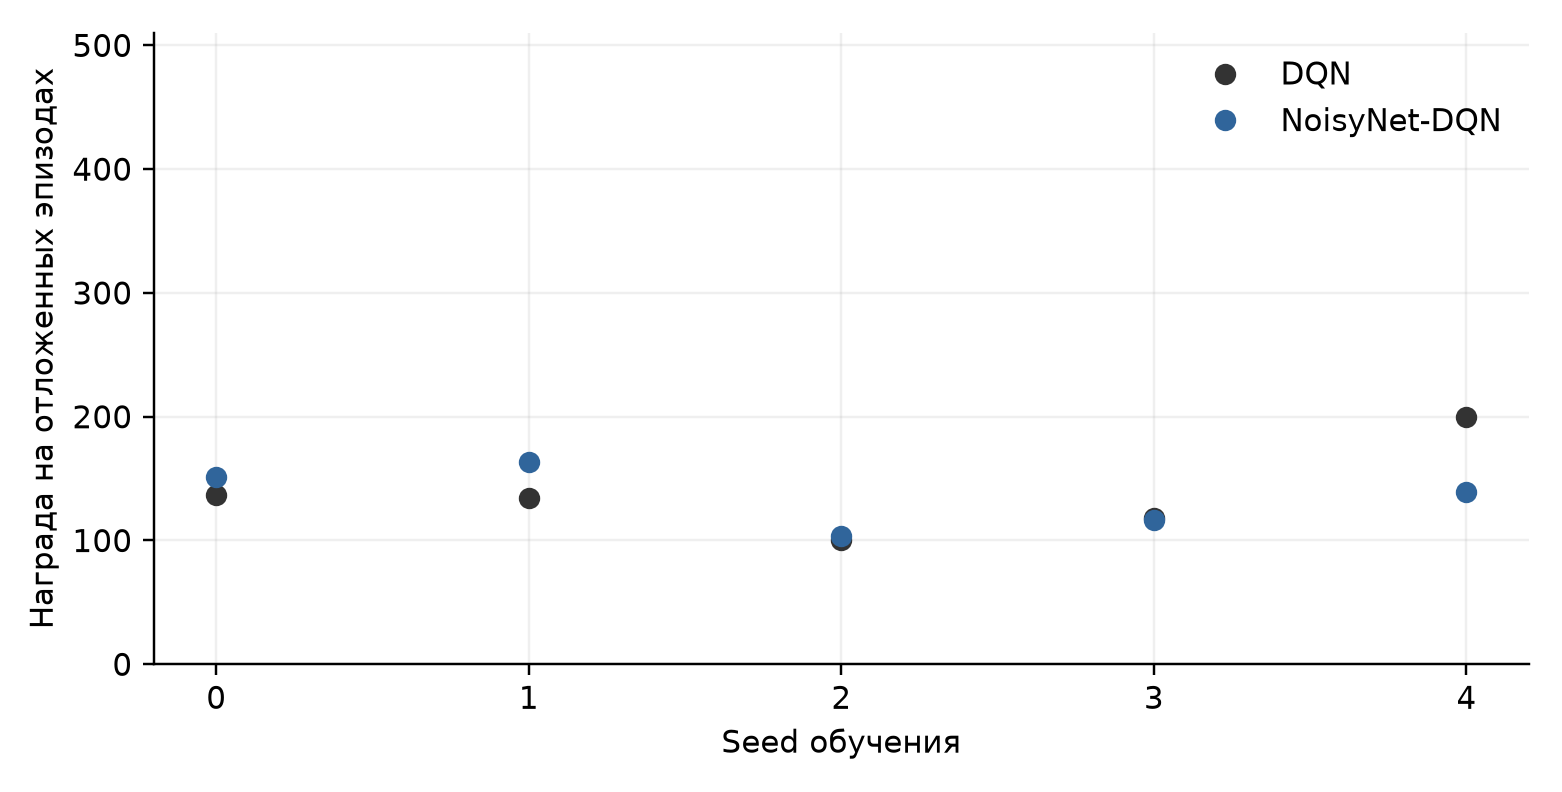

Разность NoisyNet − DQN: -3.15
Парный bootstrap-интервал 95%: [-33.89  18.8 ]


algorithm,dqn,noisy,noisy_minus_dqn
seed,,,
0,136.75,151.35,14.60
1,134.40,163.80,29.40
2,100.75,103.65,2.90
3,118.25,116.30,-1.95
4,199.95,139.25,-60.70


In [7]:
summary = summarise(runs)
aggregate = pd.DataFrame(summary["algorithms"])
display(aggregate[["algorithm", "n_seeds", "final_mean", "final_seed_sd", "auc_mean", "auc_seed_sd"]].round(2))
display(Image(filename=str(ROOT / "results/analysis/figures/final_by_seed.png")))
difference = summary["difference_noisy_minus_dqn"]
print("Разность NoisyNet − DQN:", round(difference["mean"], 2))
print("Парный bootstrap-интервал 95%:", np.round(difference["bootstrap_percentile_95"], 2))
assert difference["paired"]
paired_returns = runs.pivot(index="seed", columns="algorithm", values="final_mean")
paired_returns["noisy_minus_dqn"] = paired_returns["noisy"] - paired_returns["dqn"]
display(paired_returns.round(2))

При данном бюджете итоговые средние близки: 138,02 у DQN и 134,87 у NoisyNet-DQN. Интервал разности включает ноль. Пять запусков недостаточны для утверждения об эквивалентности методов. AUC выше у ε-жадного DQN; по этому показателю пилот не поддерживает гипотезу об ускорении обучения с помощью шума. На кривой DQN также заметно ухудшение после раннего подъёма, поэтому дополнительной проверки требует устойчивость самого базового алгоритма.

## 7. Как меняется масштаб шума

Сохранены средние абсолютные значения коэффициентов σ весов каждого шумового слоя. Это диагностическая характеристика обучаемых параметров. Её уменьшение само по себе не доказывает улучшение исследования или качества управления.

Заливка на графике показывает одно стандартное отклонение между пятью запусками.

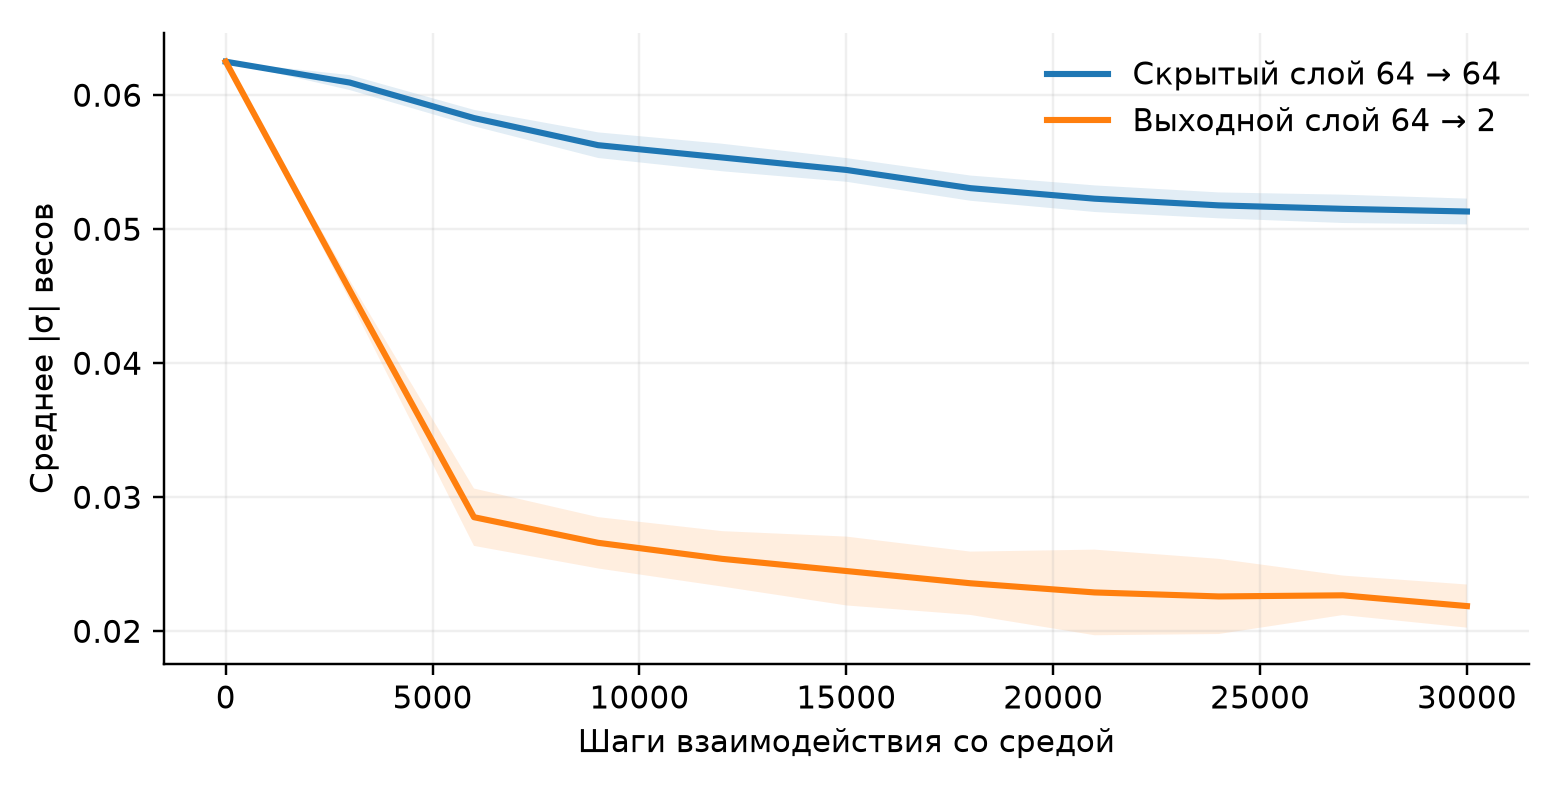

,sigma_abs_layers.2,sigma_abs_layers.4
step,,
0,0.06250,0.06250
30000,0.05132,0.02188


In [8]:
display(Image(filename=str(ROOT / "results/analysis/figures/sigma_evolution.png")))
cols = ["sigma_abs_layers.2", "sigma_abs_layers.4"]
sigma = curves.loc[curves.algorithm == "noisy"].groupby("step")[cols].mean()
display(sigma.iloc[[0, -1]].round(5))

## 8. Проверка всех сохранённых моделей

В NoisyNet можно выбирать действие по средним весам либо пересэмплировать шум. Эти политики различны. Оба режима оценены на одинаковых отложенных начальных состояниях.

Ниже заново загружаются все десять моделей. Для DQN проверяются двадцать эпизодов жадной политики, для NoisyNet — двадцать эпизодов в каждом из двух режимов. Сравниваются все отдельные награды, а не только их средние значения.

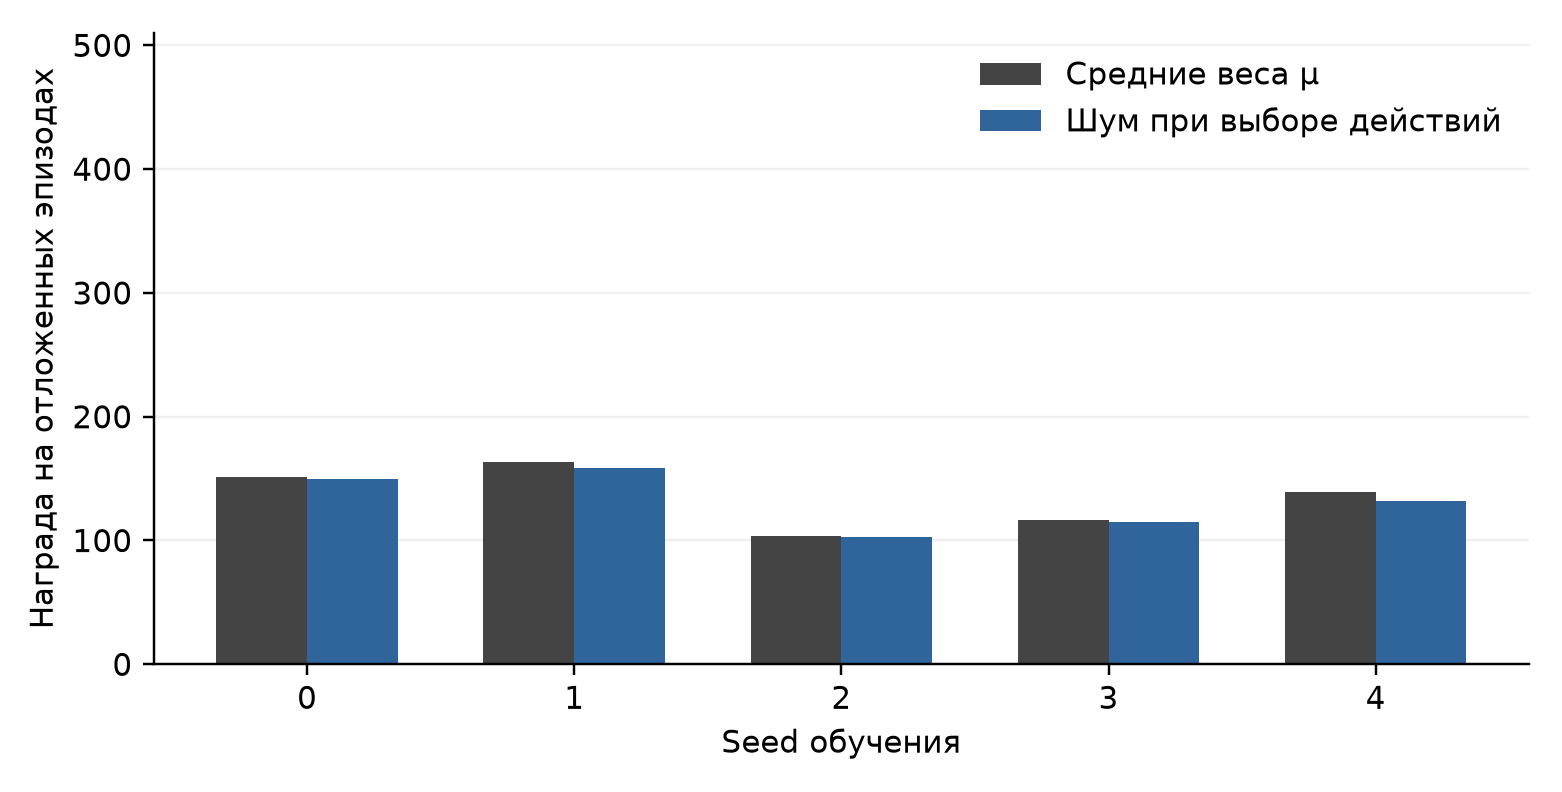

,method,seed,mode,mean_return,matches
0,dqn,0,mean_weights,136.75,True
1,dqn,1,mean_weights,134.40,True
2,dqn,2,mean_weights,100.75,True
3,dqn,3,mean_weights,118.25,True
4,dqn,4,mean_weights,199.95,True
5,noisy,0,mean_weights,151.35,True
6,noisy,0,resampled_noise,149.95,True
7,noisy,1,mean_weights,163.80,True
8,noisy,1,resampled_noise,158.80,True
9,noisy,2,mean_weights,103.65,True


Проверено 10 моделей, все 300 оценочных эпизодов воспроизведены точно.


In [9]:
display(Image(filename=str(ROOT / "results/analysis/figures/evaluation_modes.png")))
verification = []
for marker in sorted((ROOT / "results/pilot").glob("*/seed_*/COMPLETE")):
    folder = marker.parent
    model, saved_config = load_checkpoint(folder / "model.pt")
    saved = json.loads((folder / "final_returns.json").read_text())
    for mode, with_noise in [("mean_weights", False), ("resampled_noise", True)]:
        if mode not in saved:
            continue
        recomputed = evaluate(model, saved_config["env"], saved_config["final_episodes"],
                              saved_config["final_seed"], stochastic=with_noise)
        assert recomputed == saved[mode], (folder, mode)
        verification.append({"method": saved_config["algorithm"], "seed": saved_config["seed"],
                             "mode": mode, "mean_return": np.mean(recomputed), "matches": True})
assert len(verification) == 15
display(pd.DataFrame(verification).round(2))
print("Проверено 10 моделей, все 300 оценочных эпизодов воспроизведены точно.")

## 9. Ограничения и продолжение

1. CartPole даёт плотную награду; эксперимент не выделяет преимущество глубокого исследования в среде с редким подкреплением.
2. Фиксирована одна конфигурация. Наблюдаемое ухудшение DQN требует проверки learning rate, target interval и бюджета.
3. У NoisyNet больше обучаемых параметров: 8 900 против 4 610. Для изоляции обучаемого масштаба нужна абляция с фиксированным σ.
4. Основной режим оценки использует средние веса. В выводах следует отдельно учитывать стохастическую политику.
5. Пять seed и одна среда не позволяют делать общий вывод о методе.

Следующий этап: Acrobot-v1 с увеличенным бюджетом, проверка σ₀ ∈ {0,1; 0,5; 1,0}, фиксированный σ и больше независимых запусков. В репозитории есть конфигурация следующей серии, но её результаты пока не заявляются.

## Источники

- Fortunato M. et al. [Noisy Networks for Exploration](https://arxiv.org/abs/1706.10295), ICLR 2018.
- Mnih V. et al. [Playing Atari with Deep Reinforcement Learning](https://arxiv.org/abs/1312.5602), 2013.
- Farama Foundation. [CartPole](https://gymnasium.farama.org/environments/classic_control/cart_pole/) и [обработка завершения эпизодов](https://farama.org/Gymnasium-Terminated-Truncated-Step-API).
- Agarwal R. et al. [Deep Reinforcement Learning at the Edge of the Statistical Precipice](https://arxiv.org/abs/2108.13264), NeurIPS 2021.

Полный протокол запуска и пояснение структуры журналов приведены в README.